In [5]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier

In [6]:
# - SGDClassifier - 반복300회해서 구현 p1113_05.ipynb
# 2가지 모델을 사용해서 구현하시오.
# 0-red wine, 1-white wine

In [7]:
wine = pd.read_csv('data/wine.csv')
wine.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [8]:
# 2. data, label분리
data = wine[['alcohol', 'sugar', 'pH']].values
label = wine['class'].values
train_data,test_data,train_label,test_label =\
    train_test_split(data,label,random_state=42)

In [9]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [10]:
train_score = []  # train정확도값 추가
test_score = []   # test정확도값 추가
# 정답지 필요
sc = SGDClassifier(loss='log_loss',random_state=42)
classes = np.unique(train_label)
for i in range(300):
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))

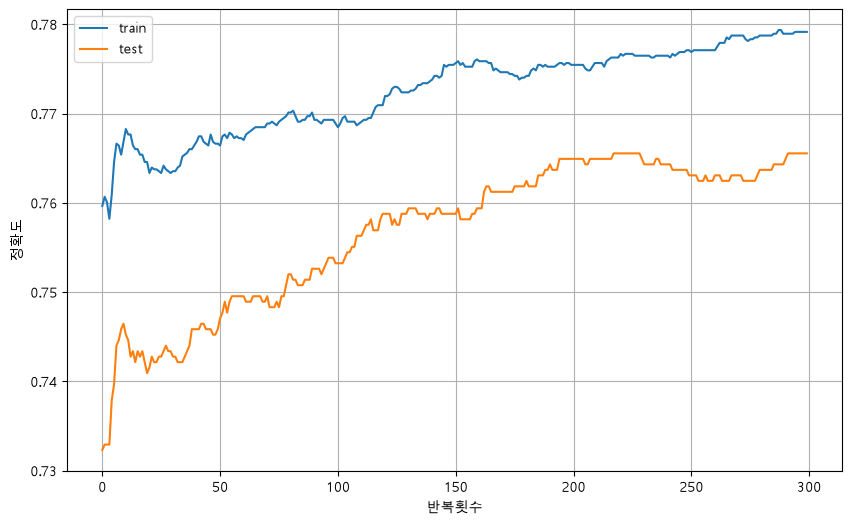

In [11]:
plt.figure(figsize=(10,6))
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('반복횟수')
plt.ylabel('정확도')
plt.grid()
plt.legend(['train','test'])
plt.show()

In [12]:
# tol : max_iter 반복할때 일정기간동안 변동이 없으면 자동으로 중지하는데 자동중지 해제
sc = SGDClassifier(loss='log_loss',max_iter=300,tol=None,random_state=42)
sc.fit(train_scaled,train_label)
print('train정확도 : ',sc.score(train_scaled,train_label))
print('test정확도 : ',sc.score(test_scaled,test_label))

train정확도 :  0.7820197044334976
test정확도 :  0.7661538461538462
